# Step 4 · Candidates and Expected Improvement

**Goal:** find which *untested* recipes are most worth testing.

1. **Candidates:** recipes within the cost ceiling, all values between 0 and 1 (so within the concentration limits). Two kinds:
   - **random:** 20,000 recipes spread evenly over all 14 components (a Latin hypercube): searches everywhere;
   - **local:** 5,000 small variations of the 5 best measured recipes: searches finely near what works.

   Why both? In 14 dimensions, random recipes almost never land on the specific combination that works, as shown below.
2. **Predict** each candidate with the GP from step 3: a mean and an uncertainty.
3. **Score** each with **Expected Improvement (EI):** *on average, by how much would this recipe beat the best so far?* Only gains count; a worse result counts as 0.

EI rewards two things:
- a **high prediction** (exploitation);
- a **high uncertainty** (exploration): a wide range includes the chance of a big win.

*Example*, with best so far = 2.5:

| Recipe | Mean | Uncertainty (sd) | EI |
|---|---|---|---|
| A | 2.6 | 0.1 (sure) | ≈ 0.11 |
| B | 2.2 | 0.6 (unsure) | ≈ 0.12 |
| C | 2.0 | 0.05 (sure) | ≈ 0 |

B, the unsure one, edges out A; C is ignored.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt

from mediaopt.acquisition import best_so_far, expected_improvement, sample_candidates, score_candidates
from mediaopt.cost import baseline_cost, media_cost
from mediaopt.data import load_recipes
from mediaopt.model import fit, make_gp

df = load_recipes()
CEILING = baseline_cost()
gp = fit(make_gp(), df)
cand = sample_candidates(df, CEILING)
print(cand.source.value_counts().to_string())

source
random    7805
local     2050


**Check:** our EI function reproduces the example table above.

In [2]:
print(expected_improvement(mean=[2.6, 2.2, 2.0], sd=[0.1, 0.6, 0.05], best=2.5).round(2))

[0.11 0.12 0.  ]


**Which "best so far"?** The best measured recipe within the ceiling scored 2.52, but the GP estimates that recipe's true growth lower: it treats part of that result as luck (step 3). If we compared the model's predictions against a lucky measurement, every candidate would look hopeless. So we compare predictions with predictions: the bar is **the model's estimate of the best recipe tested so far**.

In [3]:
BEST = best_so_far(gp, df, CEILING)
print(f"best measured within ceiling: {df[media_cost(df) <= CEILING].y.max():.2f}   model's estimate of best tested: {BEST:.2f}")

scored = score_candidates(gp, cand, BEST)
scored.groupby("source")[["mean", "sd", "ei"]].max().round(2)

best measured within ceiling: 2.52   model's estimate of best tested: 1.40


,mean,sd,ei
source,,,
local,1.52,0.76,0.33
random,0.74,1.12,0.12


The random candidates' best predicted mean is far below the local ones: random sampling alone would never find the good region.

**Three ways to pick the top-3 candidates**, to see what EI does differently:
- **highest mean:** pure exploitation;
- **highest uncertainty:** pure exploration;
- **highest EI:** the balance.

In [4]:
cols = ["source", "mean", "sd", "ei", "FBS", "Albu", "Gluta", "D", "P"]
for rule in ["mean", "sd", "ei"]:
    print(f"top 3 by {rule}:")
    print(scored.nlargest(3, rule)[cols].round(2).to_string(), "\n")

top 3 by mean:
     source  mean    sd    ei   FBS  Albu  Gluta     D     P
9298  local  1.52  0.65  0.33  0.49   0.0   1.00  0.00  1.00
9619  local  1.51  0.56  0.29  0.56   0.0   0.96  0.00  0.92
8335  local  1.51  0.59  0.29  0.48   0.0   1.00  0.01  1.00 

top 3 by sd:
      source  mean    sd    ei   FBS  Albu  Gluta     D     P
6242  random -0.22  1.12  0.04  0.01  0.80   0.04  0.04  0.48
2583  random -0.25  1.12  0.03  0.21  0.96   0.81  0.83  0.34
5301  random -0.12  1.12  0.04  0.18  0.94   0.29  0.84  0.12 

top 3 by ei:
     source  mean    sd    ei   FBS  Albu  Gluta    D     P
9298  local  1.52  0.65  0.33  0.49   0.0    1.0  0.0  1.00
8627  local  1.50  0.65  0.31  0.50   0.0    1.0  0.0  0.96
8299  local  1.47  0.66  0.30  0.44   0.0    1.0  0.0  1.00 



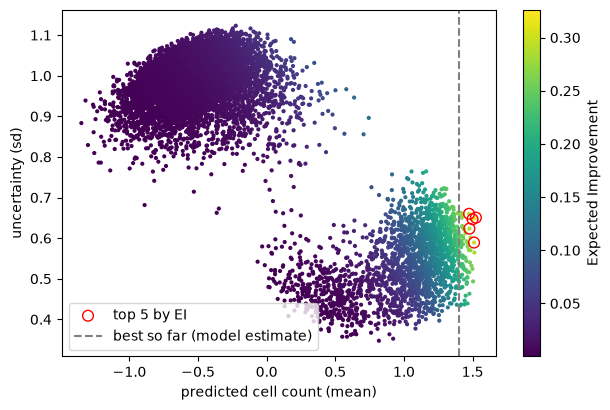

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
pts = ax.scatter(scored["mean"], scored["sd"], c=scored["ei"], s=4, cmap="viridis")
top = scored.nlargest(5, "ei")
ax.scatter(top["mean"], top["sd"], s=60, facecolors="none", edgecolors="red", label="top 5 by EI")
ax.axvline(BEST, color="grey", linestyle="--", label="best so far (model estimate)")
ax.set_xlabel("predicted cell count (mean)")
ax.set_ylabel("uncertainty (sd)")
fig.colorbar(pts, label="Expected Improvement")
ax.legend(loc="lower left")
plt.show()

**Takeaways**
- **Two clouds.**
  - The *random* candidates (upper left) are far from any tested recipe: very uncertain, and predicted poor.
  - The *local* candidates (lower right) sit near the good recipes: predicted well and less uncertain.
- **EI picks the right edge of the local cloud:** recipes predicted at or above the bar *and* still fairly uncertain. That is the explore/exploit balance in one number.
- **Pure uncertainty would waste experiments.** Its picks are random recipes full of albumin and dexamethasone, far from everything and predicted poor.
- **The top EI candidates all look alike:** FBS ≈ 0.5, no albumin, glutamine and progesterone at maximum. Testing four near-copies would teach us little, so step 5 builds a *diverse* batch and adds an explicit exploration slot.
- **Expected gains are modest** (EI ≈ 0.3 standard deviations). We are refining an already good region, not expecting a breakthrough.